# 13 · Digital control design

Two routes lead to a digital controller: design in continuous time and discretise the controller (emulation),
or discretise the plant and design in the z-domain directly. This notebook does both for the DC motor - a
Tustin-discretised lead and PID at several sampling rates, then discrete pole placement, dead-beat control,
discrete LQR and the discrete Kalman filter on the ZOH model - compares them against the continuous design,
and ends with the implementation details that decide whether the code on the microcontroller matches the
design: the computation delay, the integrator's discretisation, and the derivative filter.

**What you will learn**
- discretise a continuous controller and check the loop it really closes
- place discrete poles and design dead-beat control
- use discrete LQR and the discrete Kalman filter
- account for computation delay, integrator discretisation and derivative filtering

**Before you start:** notebooks 07, 08, 10 and 12  ·  **Time:** about 90 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, discrete as dc, design as dg, statespace as sp, response as rs, frequency as fr, stability as st, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Emulation: discretise a continuous design

continuous lead design: crossover 5 rad/s, phase margin 55.0 deg


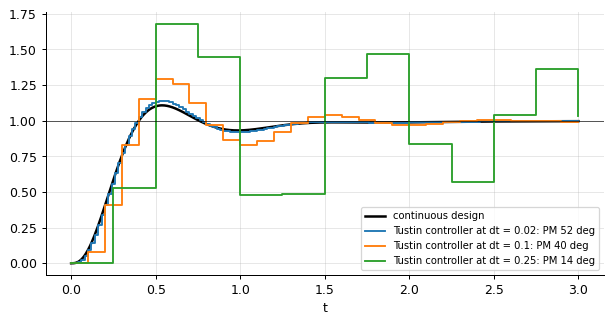

  dt  w_c dt  phase margin (deg)  overshoot %
0.02    0.10               52.12        13.82
0.10    0.50               40.28        29.20
0.25    1.25               13.93        67.94


In [2]:
mot = models.dc_motor(position=True)
P = mot["system"].to_tf()
d = dg.design_lead(P, w_c=5.0, pm_target_deg=50.0)
C = d["controller"]
print("continuous lead design: crossover 5 rad/s, phase margin", round(d["margins"]["phase_margin"], 1), "deg")
rows = []
fig, ax = plt.subplots(figsize=(8, 3.8))
t, y = rs.step(sy.feedback(sy.series(C, P)), 3.0); ax.plot(t, y, "k", lw=2, label="continuous design")
for dt in (0.02, 0.1, 0.25):
    Cd = dc.c2d(C, dt, "tustin")
    Pd = dc.c2d(P, dt)
    Ld = sy.series(Cd, Pd)
    m = fr.margins(Ld)
    td, yd = rs.step(sy.feedback(Ld), 3.0)
    ax.step(td, yd, where="post", label=f"Tustin controller at dt = {dt}: PM {m['phase_margin']:.0f} deg")
    rows.append((dt, 5.0 * dt, m["phase_margin"], rs.step_info(td, yd, final=1.0)["overshoot"]))
ax.axhline(1, color="k", lw=0.5); ax.legend(fontsize=8); ax.set_xlabel("t"); plt.show()
print(pd.DataFrame(rows, columns=["dt", "w_c dt", "phase margin (deg)", "overshoot %"]).to_string(index=False, float_format="%.2f"))

The continuous design survives emulation when ω_cΔt is small (0.1: the margin drops from 55° to 49°) and
degrades as the sampling slows: at ω_cΔt = 1.25 the hold's half-sample delay has eaten 35° of margin and the
response rings. Emulation is the quick route; its rule is the one of notebook 12, ω_cΔt ≤ 0.3, and its check
is a discrete analysis of the loop as it will really run - the ZOH plant with the discretised controller.

## Direct design on the ZOH model: pole placement and dead-beat

In [3]:
dt = 0.02
Gd = dc.c2d(mot["system"], dt)
Ad, Bd, Cd = Gd.A, Gd.B, Gd.C
s_poles = np.array([-8 + 6j, -8 - 6j, -20.0])
z_poles = np.exp(s_poles * dt)
Kz = sp.place(Ad, Bd, z_poles)
print("continuous targets", s_poles, "-> z targets", np.round(z_poles, 4), "\nplaced:", np.round(np.sort_complex(np.linalg.eigvals(Ad - Bd @ Kz)), 4))
Kdb = dc.deadbeat(Ad, Bd)
Acl_db = Ad - Bd @ Kdb
print(f"dead-beat gain {np.round(Kdb, 1)}: (A - BK)^3 = {np.max(np.abs(np.linalg.matrix_power(Acl_db, 3))):.1e} - any state is driven to zero in 3 samples")
x0 = np.array([0.0, 0.0, 0.5])      # 0.5 rad position error
for name, Kk in (("pole placement", Kz), ("dead-beat", Kdb)):
    x = x0.copy(); us = []
    for k in range(6):
        u = -(Kk @ x)[0]; us.append(u); x = Ad @ x + Bd[:, 0] * u
    print(f"{name:<15}: control sequence (V) {np.round(us, 1)}, position after 6 samples {x[2]:.2e}")

continuous targets [ -8.+6.j  -8.-6.j -20.+0.j] -> z targets [0.846 +0.102j 0.846 -0.102j 0.6703+0.j   ] 
placed: [0.6703+0.j    0.846 -0.102j 0.846 +0.102j]
dead-beat gain [[4.44000e+01 2.33170e+03 7.03466e+04]]: (A - BK)^3 = 3.0e-12 - any state is driven to zero in 3 samples
pole placement : control sequence (V) [-395.6 -230.6 -119.9  -46.9    0.    29. ], position after 6 samples 3.99e-01
dead-beat      : control sequence (V) [-35173.3  62591.3 -27668.3      0.      -0.       0. ], position after 6 samples -1.48e-31


Direct design maps the continuous specification to z = e^{sΔt} and places the poles there; the result is the
continuous design's discrete twin. Dead-beat control, with all poles at z = 0, has no continuous counterpart:
it drives any state to zero in n samples exactly - and demands, for a 0.5 rad error at Δt = 0.02, a first
control move of several thousand volts. A finite settling time in n samples is a specification about samples,
not about physics; it is useful only when Δt is long enough for the actuator to deliver.

## Discrete LQR and Kalman filter

In [4]:
Qz, Rz = np.diag([1.0, 10.0, 1000.0]), np.array([[0.1]])
rd = sp.lqr(Ad, Bd, Qz, Rz, discrete=True)
rc = sp.lqr(mot["system"].A, mot["system"].B, Qz, Rz)
print("discrete LQR poles", np.round(np.sort_complex(rd["closed_loop_poles"]), 4), "\ncontinuous LQR poles mapped by e^{s dt}:", np.round(np.sort_complex(np.exp(rc["closed_loop_poles"] * dt)), 4), "(close, not equal: the discrete cost sums, the continuous one integrates)")
kd = sp.kalman(Ad, Cd, np.diag([1e-6, 1e-4, 1e-6]), np.array([[1e-4]]), discrete=True)
print("discrete Kalman gain (predictor form)", np.round(kd["L"].ravel(), 4), "estimator poles", np.round(np.abs(kd["estimator_poles"]), 4))

discrete LQR poles [0.8188+0.j 0.8944+0.j 0.9308+0.j] 
continuous LQR poles mapped by e^{s dt}: [0.8188+0.j 0.8943+0.j 0.9309+0.j] (close, not equal: the discrete cost sums, the continuous one integrates)
discrete Kalman gain (predictor form) [0.0003 0.1141 0.1214] estimator poles [0.9607 0.8494 0.8494]


The discrete LQR minimises a sum instead of an integral; its poles sit near, but not exactly at, the images of
the continuous LQR's. The discrete Kalman filter is the natural form on sampled data (notebook 11 ran it); in
predictor form its gain multiplies the innovation y_k − Cx̂_k to produce x̂_{k+1}, so the estimate used for
control at step k + 1 is available before the measurement at that step is taken - a full sample of latency
that the current-estimator form avoids.

## Implementation details that change the loop

In [5]:
dt = 0.02
Cz_back = dc.pid_discrete(3.0, 2.0, 0.3, dt, method="backward")
Cz_tust = dc.pid_discrete(3.0, 2.0, 0.3, dt, method="tustin")
C_cont = dg.pid(3.0, 2.0, 0.3)
w = np.logspace(-1, np.log10(np.pi / dt), 300)
for name, Cz in (("backward-rectangle integral", Cz_back), ("Tustin integral", Cz_tust)):
    print(f"{name:<28}: |C_d - C| at w = 1: {abs(fr.freqresp(Cz, 1.0) - fr.freqresp(C_cont, 1.0)):.4f}, at w = 50: {abs(fr.freqresp(Cz, 50.0) - fr.freqresp(C_cont, 50.0)):.3f}")
Pd = dc.c2d(mot["system"].to_tf(), dt)
Cz_lead = dc.c2d(C, dt, "tustin")                                   # the lead design of the first section (crossover 5 rad/s)
for comp_delay in (0.0, 1.0):
    Lz = sy.series(Cz_lead, Pd)
    if comp_delay:
        Lz = sy.series(Lz, sy.tf([1.0], [1.0, 0.0], dt))           # one sample of computation delay: 1/z
    m = fr.margins(Lz)
    print(f"lead loop with computation delay {comp_delay:.0f} sample(s): phase margin {m['phase_margin']:.1f} deg at w_gc = {m['w_gc']:.2f} rad/s (one sample at w_gc costs w_gc dt = {np.degrees(m['w_gc'] * dt):.1f} deg)")

backward-rectangle integral : |C_d - C| at w = 1: 0.0230, at w = 50: 5.025
Tustin integral             : |C_d - C| at w = 1: 0.0030, at w = 50: 5.016
lead loop with computation delay 0 sample(s): phase margin 52.1 deg at w_gc = 5.00 rad/s (one sample at w_gc costs w_gc dt = 5.7 deg)
lead loop with computation delay 1 sample(s): phase margin 46.4 deg at w_gc = 5.00 rad/s (one sample at w_gc costs w_gc dt = 5.7 deg)


Two discretisations of the same PID differ by a fraction of a percent at the loop's frequencies and by more
near the Nyquist frequency; the choice matters little compared with the computation delay. If the control
computed from the sample at k is applied only at k + 1, a full sample of delay enters the loop - ω_cΔt radians,
here 6° of phase margin at Δt = 0.02 with a 5 rad/s crossover, and proportionally more at slower rates. Reading the sensor, computing and writing
the actuator within a small fraction of the sample period, in that order, is the implementation rule that
keeps the design valid.

## Inside the algorithm: the dead-beat gain as a pole placement at z = 0

In [6]:
Kdb_hand = sp.acker(Ad, Bd, [0.0, 0.0, 0.0])
print("Ackermann with all poles at 0:", np.round(Kdb_hand, 1), " library:", np.round(Kdb, 1))

Ackermann with all poles at 0: [[4.44000e+01 2.33170e+03 7.03466e+04]]  library: [[4.44000e+01 2.33170e+03 7.03466e+04]]


## Exercises
1. Implement the DC motor position loop as a discrete LQR with integral action at dt = 0.02 (augment the ZOH model with a discrete integrator of the error) and compare its tracking of a 1 rad step and its rejection of a load torque with the emulated lead design.
2. Add a one-sample computation delay to the plant model (a state z^-1) and redesign the discrete pole placement for the delayed model. How does the achievable speed compare with the delay-free design at dt = 0.02 and at dt = 0.1?
3. **Implement it yourself:** write the discrete PID as a difference equation (u[k] from e[k], e[k-1], e[k-2] and u[k-1], u[k-2]) from the coefficients of `discrete.pid_discrete` and verify it against `response.step` of the controller transfer function.